In [93]:
import pennylane as qml
from pennylane import math as qml_math
from pennylane import numpy as np
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.visualization import array_to_latex
from typing import Callable
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from functools import reduce
from scipy.stats import wasserstein_distance

In [94]:
rng = np.random.default_rng(42)

In [95]:
dev = qml.device("default.qubit")
# dev = qml.device("default.mixed")
# dev = qml.device("default.qubit", shots=100)

In [96]:
def is_unitary(m: np.ndarray):
    return np.allclose(np.eye(m.shape[0]), m * m.T.conj())

In [97]:
def get_U_from_state(state: np.ndarray):
    
    @qml.qnode(dev)
    def circuit(wires: list[int]):
        qml.StatePrep(state, wires=wires, normalize=False)
        return qml.state()
    
    d_wires = int(np.log2(len(state)))
    wires = list(range(d_wires))
    # print(f"{wires=}")
    
    # qml.draw_mpl(circuit, wire_order=wires, style="pennylane", level='device')(wires)
    return qml.matrix(circuit, wire_order=wires)(wires)

In [98]:
from typing import Any


@qml.qnode(dev)
def circuit(
    wires: list[int],
    # func_prepare: Callable[[list[int]], None]=None,
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    # qml.adjoint(qml.QFT(wires=wires))
    # qml.QFT(wires=wires)
    # return qml.state(), qml.probs(wires=wires)
    # m = qml.measure(wires=wires_actions_returns[0], postselect=0)
    # return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)
    # return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires), qml.probs(wires=[1,2])
    # return (qml.density_matrix(wires=wlist) for wlist in wires_actions_returns)

In [99]:
def prepare_action_returns(
    wires: list[int], 
    action_probs_vec: np.ndarray, # shape (n_actions,),
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    ):
    # print(f"{action_probs_vec.shape=}")
    # print(f"{returns_probs_matrix.shape=}")
    n_actions = action_probs_vec.shape[0]
    n_returns = returns_probs_matrix.shape[1]
    
    # Get number of qubits needed for actions and returns.
    # (for now) The number of actions and returns must be powers of 2 for this to work properly.
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Partition wires into action and return wires.
    # Wire order is: [action wires, return wires]
    if len(wires) != d_actions + d_returns:
        raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
    wires_action = wires[:d_actions]
    wires_returns = wires[d_actions:]
    # print(f"{wires_action=}, {wires_returns=}")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_action, normalize=False) # Must normalize since inputs are probability vectors.
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=False) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_action)

In [100]:
from pennylane.wires import Wires, WiresLike
import inspect
import functools

class CustomQFT(qml.QFT):

    
    @staticmethod
    def compute_decomposition(wires: WiresLike):  # pylint: disable=arguments-differ,unused-argument
        r"""Representation of the operator as a product of other operators (static method).

        .. math:: O = O_1 O_2 \dots O_n.


        .. seealso:: :meth:`~.QFT.decomposition`.

        Args:
            wires (Iterable, Wires): wires that the operator acts on

        Returns:
            list[Operator]: decomposition of the operator

        **Example:**

        >>> qml.QFT.compute_decomposition(wires=(0,1,2))
        [H(0),
         ControlledPhaseShift(1.5707963267948966, wires=Wires([1, 0])),
         ControlledPhaseShift(0.7853981633974483, wires=Wires([2, 0])),
         H(1),
         ControlledPhaseShift(1.5707963267948966, wires=Wires([2, 1])),
         H(2),
         SWAP(wires=[0, 2])]

        """
        print("compute_decomposition")
        wires = Wires(wires)
        n_wires = len(wires)

        shifts = [2 * np.pi * 2**-i for i in range(2, n_wires + 1)]
        # shifts = [20 for i in range(2, n_wires + 1)]

        shift_len = len(shifts)
        decomp_ops = []
        for i, wire in enumerate(wires):
            decomp_ops.append(qml.Hadamard(wire))

            for shift, control_wire in zip(shifts[: shift_len - i], wires[i + 1 :]):
                op = qml.ControlledPhaseShift(shift, wires=[control_wire, wire])
                decomp_ops.append(op)

        first_half_wires = wires[: n_wires // 2]
        last_half_wires = wires[-(n_wires // 2) :]

        for wire1, wire2 in zip(first_half_wires, reversed(last_half_wires)):
            swap = qml.SWAP(wires=[wire1, wire2])
            decomp_ops.append(swap)

        return decomp_ops

In [101]:
n_actions = 4
n_returns = 8
d_actions = int(np.log2(n_actions))
d_returns = int(np.log2(n_returns))

In [202]:
returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

In [203]:
# n_actions = 4
# n_returns = 8
# d_actions = int(np.log2(n_actions))
# d_returns = int(np.log2(n_returns))
########
# action_probs_vec = np.abs(rng.normal(0, 1, size=(n_actions,)))
action_probs_vec = [1./n_actions] * n_actions  # Uniform distribution for simplicity
### Use action probabilities measured from previous circuit output (if a previous run exists).
# if 'probs_actions' not in globals(): # No previous run exists.
#     action_probs_vec = [1./n_actions] * n_actions  # Uniform distribution for simplicity
# else: # A previous circuit run exists.
#     action_probs_vec = (probs_actions)/((probs_actions).sum())
# action_probs_vec = action_probs_vec / np.sum(action_probs_vec)  # Normalize to make it a probability vector
action_probs_vec = np.array(action_probs_vec)
######
# action_probs_vec = [0.7, 0.1, 0.1, 0.1]  # Higher priority for action a0, lower for others.
# action_probs_vec = [0.1, 0.7, 0.1, 0.1]  # Higher priority for action a0, lower for others.
# action_probs_vec = [0, 0, 0.5, 0.5]  # Only consider actions [a2, a3].
# action_probs_vec = [0, 0.5, 0, 0.5]  # Only consider actions [a2, a3].
# action_probs_vec = [0, 0.33, 0.33, 0.33]  # Only consider actions [a2, a3].
# action_probs_vec = [0, 0, 0.2, 0.8]
# action_probs_vec = [0, 0, 0, 1]
# action_probs_vec = [0, 0, 1, 0]
# action_probs_vec = [0.1, 0.4, 0.1, 0.4]
# action_probs_vec = [0.1, 0.4, 0.4, 0.1]
# action_probs_vec = action_probs_vec / np.sum(action_probs_vec)  # Normalize to make it a probability vector
# returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
# returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

#### TESTING - do some row swapping.
# returns_probs_matrix[[0, 3]] = returns_probs_matrix[[3, 0]]
# returns_probs_matrix[[1, 3]] = returns_probs_matrix[[3, 1]]
# _r1 = returns_probs_matrix[1]
# _r3 = returns_probs_matrix[3]
# returns_probs_matrix[1] = _r3
# returns_probs_matrix[3] = _r1

returns_atoms_values = np.exp(np.array([float(i)+1 for i in range(n_returns)]))
returns_atoms_values = returns_atoms_values/np.sum(returns_atoms_values) # Normalize to make it a probability vector (sums to 1).

# U_returns_atoms = np.diag(returns_atoms_values)
# U_returns_atoms = np.diag(returns_atoms_values/np.sum(returns_atoms_values))
U_returns_atoms = np.diag(np.sqrt(returns_atoms_values))
# U_returns_atoms = get_U_from_state(np.sqrt(returns_atoms_values))
# Q, R = np.linalg.qr(np.diag(np.sqrt(returns_atoms_values)))
# U_returns_atoms = Q

wires = list(range(d_actions + d_returns))
wires_actions = wires[:d_actions]
wires_returns = wires[d_actions:]

funcs = [
    # lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix), # Prepare the action and return distributions.
    # lambda wires: qml.adjoint(qml.QFT(wires=wires_actions)),
    lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix), # Prepare the action and return distributions.
    # lambda wires: qml.QFT(wires=wires_actions),
    # lambda wires: CustomQFT.compute_decomposition(wires=wires),
    # lambda wires: CustomQFT.compute_decomposition(wires=wires_returns),
    # lambda wires: qml.GroverOperator(wires=wires_returns),
    # lambda wires: qml.QFT(wires=wires),
    # lambda wires: qml.QFT(wires=wires_actions),
    # lambda wires: qml.QFT(wires=wires_returns),
    # lambda wires: qml.QFT(wires=wires),
    # lambda wires: qml.QFT(wires=wires_returns),
    # lambda wires: qml.adjoint(qml.QFT(wires=wires_returns)),
    # lambda wires: qml.StatePrep(np.sqrt(returns_atoms_values), wires=wires_returns, normalize=False),
    lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    #####
    # lambda wires: qml.adjoint(qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True)),
    # lambda wires: qml.adjoint(qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True)),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(get_U_from_state(returns_atoms_values/np.linalg.norm(returns_atoms_values)), wires=wires_returns),
    # lambda wires: qml.QubitUnitary(get_U_from_state(np.sqrt(returns_atoms_values)), wires=wires_returns),
    # lambda wires: qml.adjoint(qml.QubitUnitary(get_U_from_state(np.sqrt(returns_atoms_values)), wires=wires_returns)),
    # lambda wires: qml.QFT(wires=wires_returns),
    # lambda wires: qml.QFT(wires=wires_returns),
    # lambda wires: qml.QFT(wires=wires),
    #############
    # lambda wires: qml.adjoint(qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True)),
    # lambda wires: qml.adjoint(qml.QFT(wires=wires_returns)),
    # lambda wires: qml.adjoint(qml.QFT(wires=wires)),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QFT(wires=wires_returns),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QFT(wires=wires_returns),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
    # lambda wires: qml.QFT(wires=wires_returns),
]
func_measure = lambda wires: (
    qml.state(),
    qml.probs(wires=wires),
    qml.density_matrix(wires),
    qml.probs(wires=wires_actions),
    qml.probs(wires=wires_returns),
    ) # Tuple of measurements: state, probs, density matrix, probs actions, probs returns.
state, probs, rho, probs_actions, probs_returns = circuit(wires, funcs=funcs, func_measure=func_measure)

print(f"{wires_actions=}")
print(f"{wires_returns=}")
print(f"{probs_actions=}")
print(f"{probs_returns=}")
print(f"{probs=}")

# Split the system density matrix into density matrices for the actions and returns subsystems.
# rho_actions = partial_trace(DensityMatrix(rho), qargs=wires_returns) # This is the reduced density matrix for actions, trace out the returns.
rho_actions = qml_math.partial_trace(rho, indices=wires_returns) # This is the reduced density matrix for actions, trace out the returns.
# rho_returns = partial_trace(DensityMatrix(rho), qargs=wires_actions) # This is the reduced density matrix for returns, trace out the actions.
rho_returns = qml_math.partial_trace(rho, indices=wires_actions) # This is the reduced density matrix for returns, trace out the actions.

# print("State:", state)
# print("Probabilities:", probs
# print("Distribution:", dist**2)

display(array_to_latex(action_probs_vec, prefix="\\textrm{Action probabilities vector:~~}"))
display(array_to_latex(returns_probs_matrix, prefix="\\textrm{Returns probabilities matrix:~~}"))
display(array_to_latex(returns_atoms_values, prefix="\\textrm{Returns atoms values:~~}"))
display(array_to_latex(returns_probs_matrix @ returns_atoms_values, prefix="\\textrm{Action expected returns (return dist @ return values):~~}"))
# display(array_to_latex(state, prefix="\\textrm{State:~~}"))
display(Statevector(state).draw(output='latex', prefix="\\textrm{State:~~}"))
display(array_to_latex(probs, prefix="\\textrm{Probabilities:~~}"))
display(DensityMatrix(rho).draw(output='latex', prefix="\\textrm{Rho:~~}"))
# display(array_to_latex(rho_actions, prefix="\\textrm{Rho actions:~~}"))
display(DensityMatrix(rho_actions).draw(output='latex', prefix="\\textrm{Rho actions:~~}"))
# display(array_to_latex(rho_returns, prefix="\\textrm{Rho returns:~~}"))
display(DensityMatrix(rho_returns).draw(output='latex', prefix="\\textrm{Rho returns:~~}"))

wires_actions=[0, 1]
wires_returns=[2, 3, 4]
probs_actions=tensor([0.01896768, 0.0301243 , 0.04145659, 0.02159412], requires_grad=True)
probs_returns=tensor([7.45139109e-05, 1.25162191e-04, 4.99863893e-04, 1.18753117e-03,
        4.94592783e-03, 1.35924368e-02, 4.05094721e-02, 5.12077854e-02], requires_grad=True)
probs=tensor([1.80725045e-05, 3.69152971e-05, 2.94506527e-04, 3.08936757e-04,
        8.57262616e-04, 2.50936373e-03, 7.03756263e-03, 7.90506180e-03,
        5.09775142e-06, 3.60609681e-06, 1.57460375e-04, 2.91588515e-04,
        8.08454095e-04, 5.91977245e-03, 1.67787012e-02, 6.15961505e-03,
        4.38921270e-05, 1.20884634e-05, 2.43665124e-05, 1.59574976e-04,
        1.98198828e-03, 9.05010863e-04, 4.60798664e-03, 3.37216838e-02,
        7.45152801e-06, 7.25523333e-05, 2.35304778e-05, 4.27430919e-04,
        1.29822284e-03, 4.25828974e-03, 1.20852216e-02, 3.42142475e-03], requires_grad=True)


/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/ops/qubit/matrix_ops.py:170: UserWarning: Operator [[0.02401276 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.03959035 0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.06527346 0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.10761774 0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.17743165 0.
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.29253534
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.48230923 0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.79519349]]
 may not be unitary. Verify unitarity of operation, or use a datatype with increased precision.
  warnings.warn(


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [204]:
np.linalg.svd(U_returns_atoms)
np.linalg.norm(U_returns_atoms) # == 1

np.float64(0.9999999999999999)

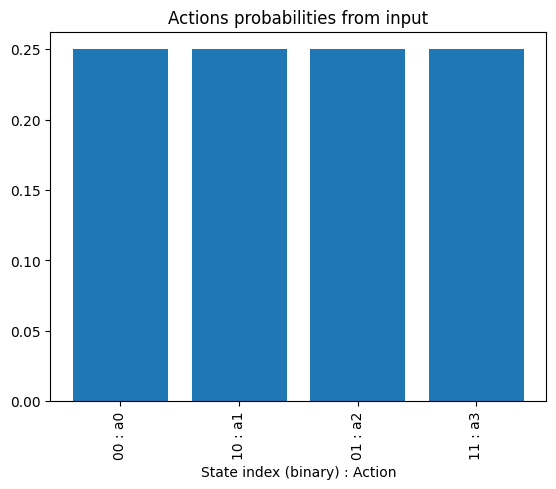

<Figure size 640x480 with 0 Axes>

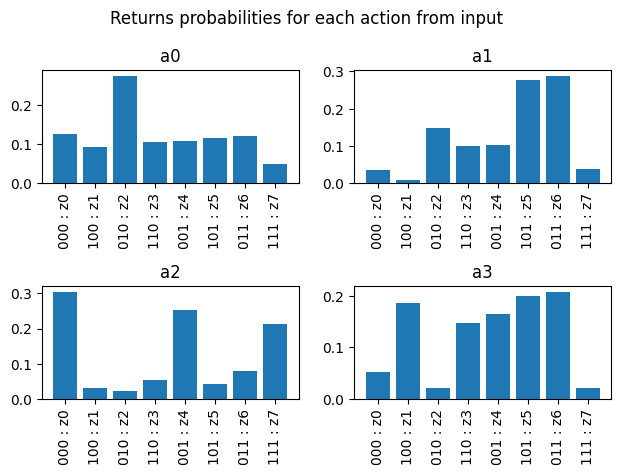

Text(0.5, 0, 'State index (binary) : Action')

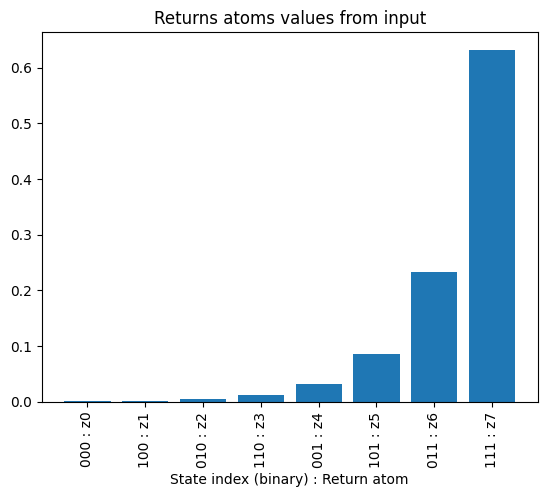

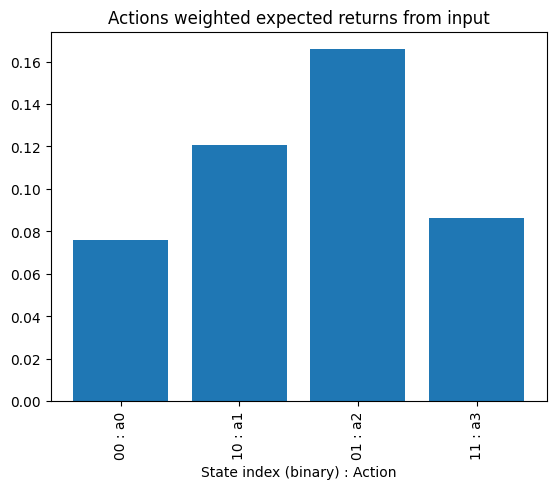

In [205]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(np.arange(n_actions), action_probs_vec)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions probabilities from input")
plt.xlabel("State index (binary) : Action")


plt.figure()
fig, axs = plt.subplots(d_actions, d_actions)
axs = axs.flatten()
for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), returns_probs_matrix[a])
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}")
plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()


plt.figure()
plt.bar(np.arange(n_returns), returns_atoms_values)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Returns atoms values from input")
plt.xlabel("State index (binary) : Return atom")


plt.figure()
plt.bar(np.arange(n_actions), returns_probs_matrix @ returns_atoms_values)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions weighted expected returns from input")
plt.xlabel("State index (binary) : Action")

/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/ops/qubit/matrix_ops.py:170: UserWarning: Operator [[0.02401276 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.03959035 0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.06527346 0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.10761774 0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.17743165 0.
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.29253534
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.48230923 0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.79519349]]
 may not be unitary. Verify unitarity of operation, or use a datatype with increased precision.
  warnings.warn(


(<Figure size 11800x600 with 1 Axes>, <Axes: >)



In [206]:
# print(qml.draw(circuit, wire_order=wires, level='device')(wires, wires_actions_returns=(wires_actions, wires_returns), func_prepare=f))
qml.draw_mpl(circuit, wire_order=wires, style="pennylane", level='device')(wires, funcs=funcs)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_76134/1679482983.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)


Text(0.5, 1.0, 'Mean return probabilities across all actions from input')

<Figure size 640x480 with 0 Axes>

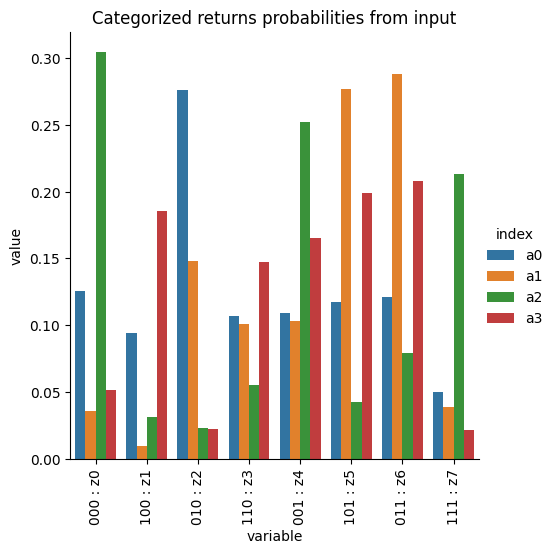

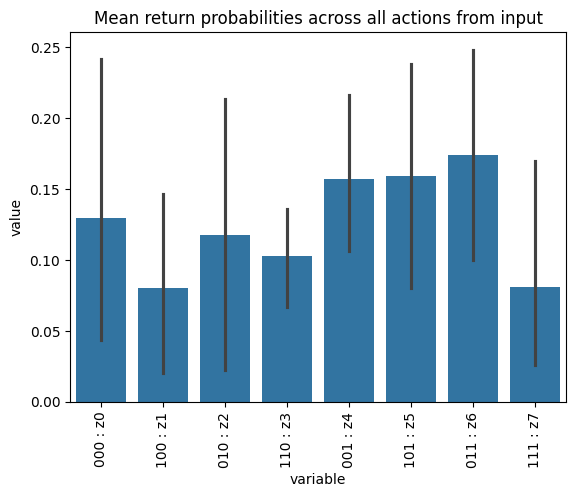

In [207]:
# Create a DataFrame from the returns probabilities matrix for visualization.
df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
df = df.reset_index()
df = df.melt(id_vars='index')

# Plot the categorized returns probabilities matrix.
plt.figure()
ax = sns.catplot(data=df, x='variable', y='value', hue='index', kind="bar", legend=True)
ax.set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Categorized returns probabilities from input")

# Plot the average returns probabilities matrix as a bar plot with error bars.
plt.figure()
ax = sns.barplot(data=df, x='variable', y='value')
ax.set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Mean return probabilities across all actions from input")

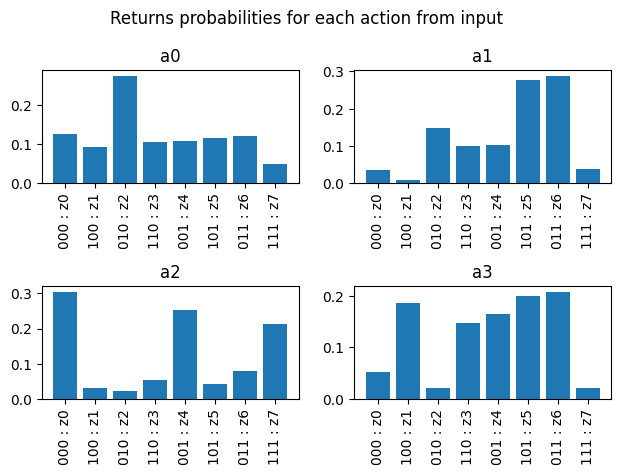

In [208]:
### Plot the returns probabilities matrix for each action individually.

fig, axs = plt.subplots(d_actions, d_actions)
axs = axs.flatten()

for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), returns_probs_matrix[a])
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}")

plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()

Text(0.5, 0, 'State index (binary) : Return atom')

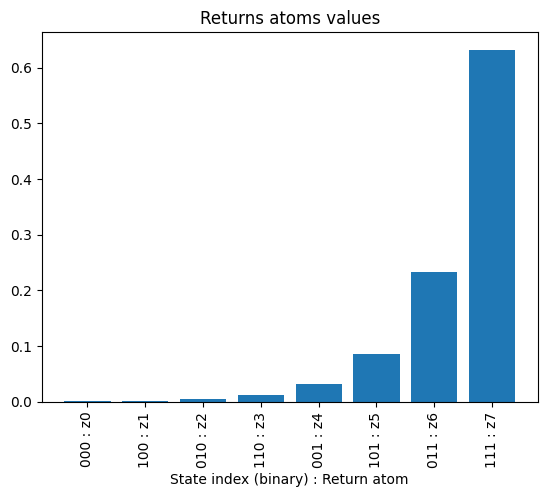

In [209]:
### Plot the returns atoms values.

plt.bar(np.arange(n_returns), returns_atoms_values)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Returns atoms values")
plt.xlabel("State index (binary) : Return atom")

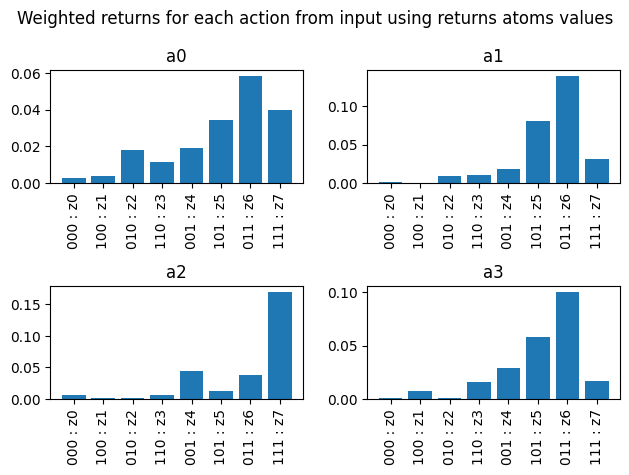

In [210]:
### Plot result of passing action returns distributions through returns atoms values operation.

fig, axs = plt.subplots(d_actions, d_actions)
axs = axs.flatten()

for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), np.abs(U_returns_atoms @ returns_probs_matrix[a]))
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}")

plt.suptitle("Weighted returns for each action from input using returns atoms values")
plt.tight_layout()
plt.show()

In [211]:
np.abs(np.einsum('jj,ij->i', U_returns_atoms, returns_probs_matrix))

tensor([0.18803827, 0.29100809, 0.28085725, 0.23083204], requires_grad=True)

Text(0.5, 0, 'State index (binary) : Return atom')

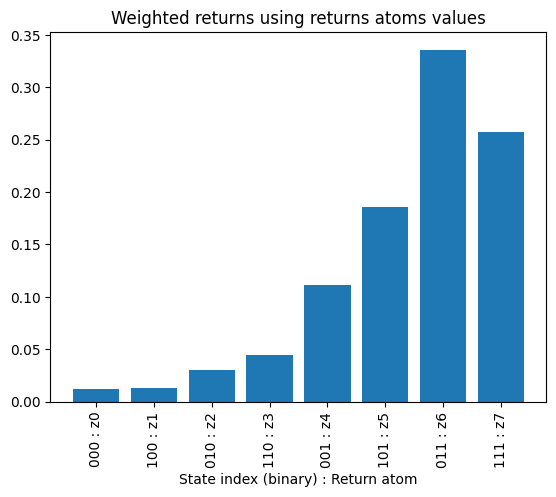

In [212]:
# M = np.sum(U_returns_atoms * returns_probs_matrix[:,None,:], axis=1)
# U_returns_atoms @ returns_probs_matrix[:,None,:]

M = np.einsum('jj,ij->j', U_returns_atoms, returns_probs_matrix)

plt.bar(np.arange(n_returns), np.abs(M))
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Weighted returns using returns atoms values")
plt.xlabel("State index (binary) : Return atom")

Text(0.5, 0, 'State index (binary) : Return atom')

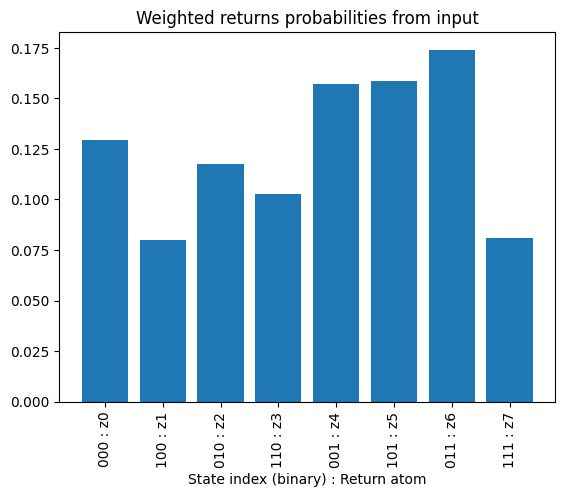

In [213]:
### Compute weighted returns probabilities using the action probabilities vector as weights.

df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
weighted_vec = (df.T * weights).sum(axis=1).to_numpy()

plt.bar(np.arange(n_returns), weighted_vec)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Weighted returns probabilities from input")
plt.xlabel("State index (binary) : Return atom")

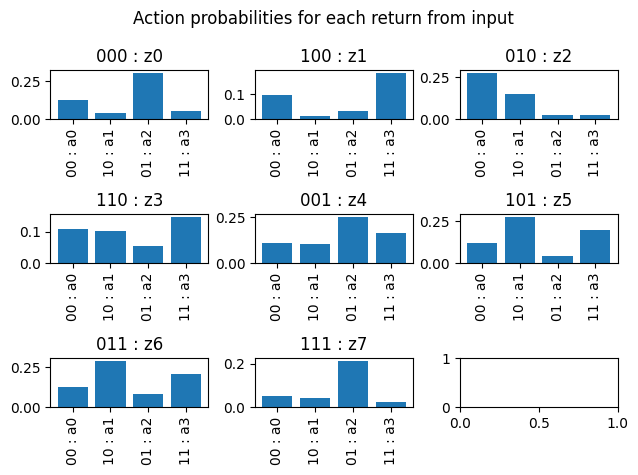

In [214]:
#### Plot the transpose, actions as columns, returns as rows.


fig, axs = plt.subplots(d_returns, d_returns)
axs = axs.flatten()

for r in range(n_returns):
    axs[r].bar(np.arange(n_actions), returns_probs_matrix[:, r])
    axs[r].set_xticks(np.arange(n_actions))
    axs[r].set_xticklabels([f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
    axs[r].set_title(f"{r:0{d_returns}b}"[::-1] + f" : z{r}")

plt.suptitle("Action probabilities for each return from input")
plt.tight_layout()
plt.show()

Text(0.5, 0, 'State index (binary) : Action atom')

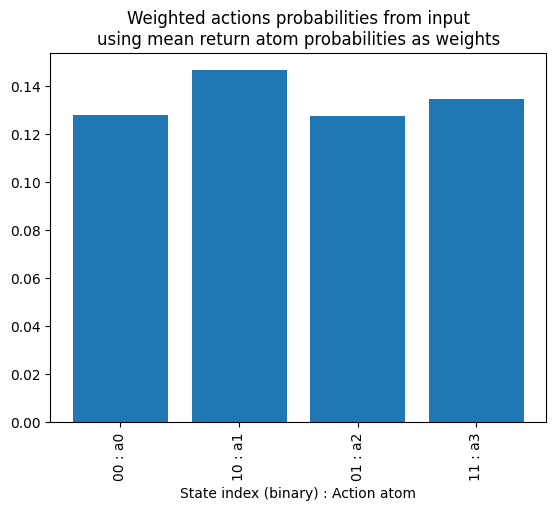

In [215]:
# ### Compute weighted action probabilities using the mean return atom probabilities vector as weights.

df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)]) # (actions, returns)
df = df.T # (returns, actions)
weights = pd.Series(returns_probs_matrix.mean(axis=0), index=[f"z{i}" for i in range(n_returns)])
weighted_vec = (df.T * weights).sum(axis=1).to_numpy()

# print(f"{weights=}")
# print(f"{weights.sum()=}")
# print(f"{weighted_vec=}")
# print(f"{weighted_vec.sum()=}")

# df.T * weights

plt.bar(np.arange(n_actions), weighted_vec)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Weighted actions probabilities from input\nusing mean return atom probabilities as weights")
plt.xlabel("State index (binary) : Action atom")

Text(0.5, 0, 'State index (binary) : Return atom')

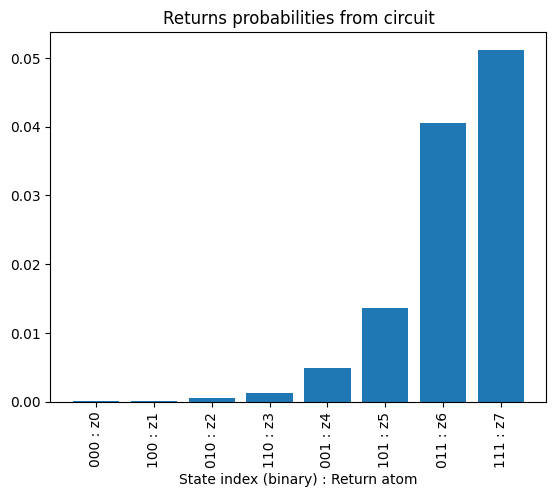

In [216]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_returns), probs_returns)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Returns probabilities from circuit")
plt.xlabel("State index (binary) : Return atom")

Distance from sampled returns to action 0 returns: 0.11098216333327643
Distance from sampled returns to action 1 returns: 0.11098216333327643
Distance from sampled returns to action 2 returns: 0.11098216333327643
Distance from sampled returns to action 3 returns: 0.11098216333327643


Text(0.5, 1.0, 'Wasserstein distance between sampled returns from circuit and input action returns\n(lower distance means closer match)')

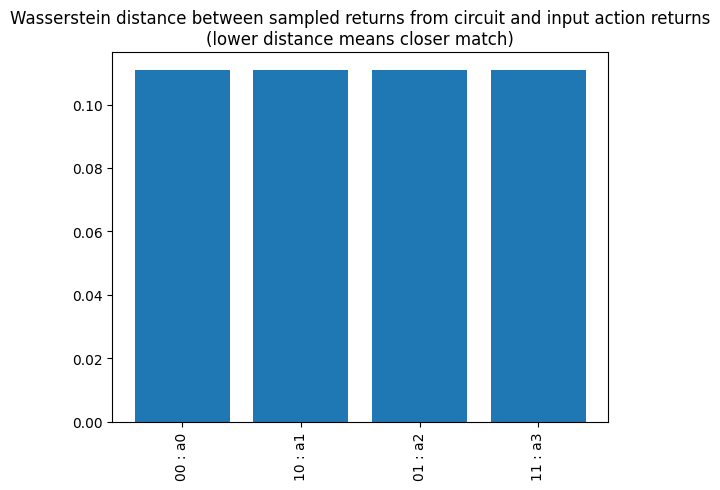

In [217]:
### Measure the distance from the sampled distribution to each of the action return distributions.

distances = []
for i in range(n_actions):
    dist = wasserstein_distance(probs_returns, returns_probs_matrix[i])
    distances.append(dist)
    print(f"Distance from sampled returns to action {i} returns: {dist}")
plt.bar(np.arange(n_actions), distances)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Wasserstein distance between sampled returns from circuit and input action returns\n(lower distance means closer match)")

Text(0.5, 0, 'State index (binary) : Action')

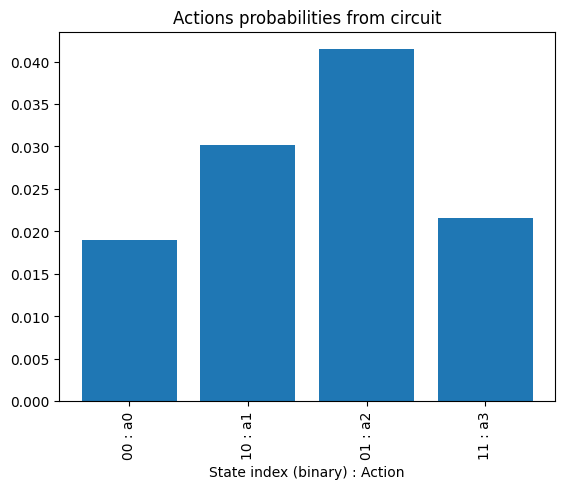

In [218]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions probabilities from circuit")
plt.xlabel("State index (binary) : Action")

Text(0.5, 0, 'State index (binary) : Action')

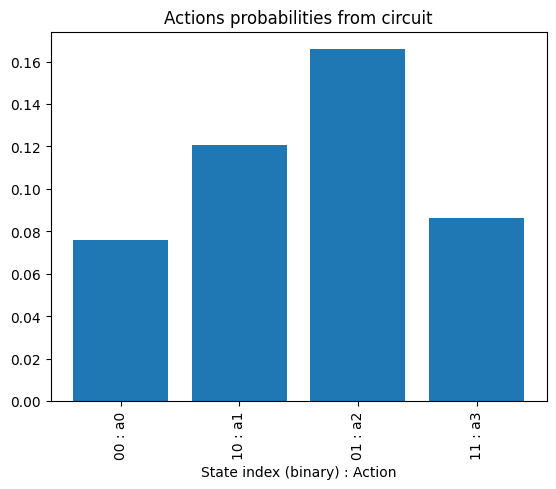

In [219]:
plt.bar(np.arange(n_actions), probs_actions*n_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions probabilities from circuit")
plt.xlabel("State index (binary) : Action")

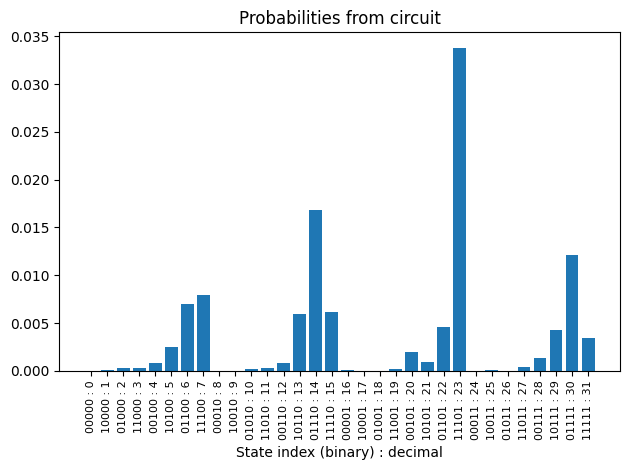

In [220]:
### Probabilities derived from measuring the returns qubits in the circuit.
n_states = 2**len(wires)
plt.bar(np.arange(n_states), probs)
plt.xticks(np.arange(n_states), [f"{i:0{len(wires)}b}"[::-1] + f" : {i}" for i in range(n_states)], fontsize=8, rotation=90)
plt.xlabel("State index (binary) : decimal")

plt.title("Probabilities from circuit")

plt.tight_layout()

In [221]:
######
#### KEEP FOR LATER JUST IN CASE.
######

# ### Probabilities derived from reduced density matrix of returns subsystem.

# # DensityMatrix(rho_returns).probabilities()
# plt.bar(np.arange(n_returns), DensityMatrix(rho_returns).probabilities())
# plt.xticks(np.arange(n_returns), [f"z{i}" for i in range(n_returns)])
# plt.title("Returns probabilities derived from reduced density matrix of returns subsystem")